In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt

# Практические задания

#### 1. Графики 5 распределений. Постройте PDF/PMF для Бернулли, Биномиального, Нормального, Пуассона, Экспоненциального с несколькими наборами параметров.

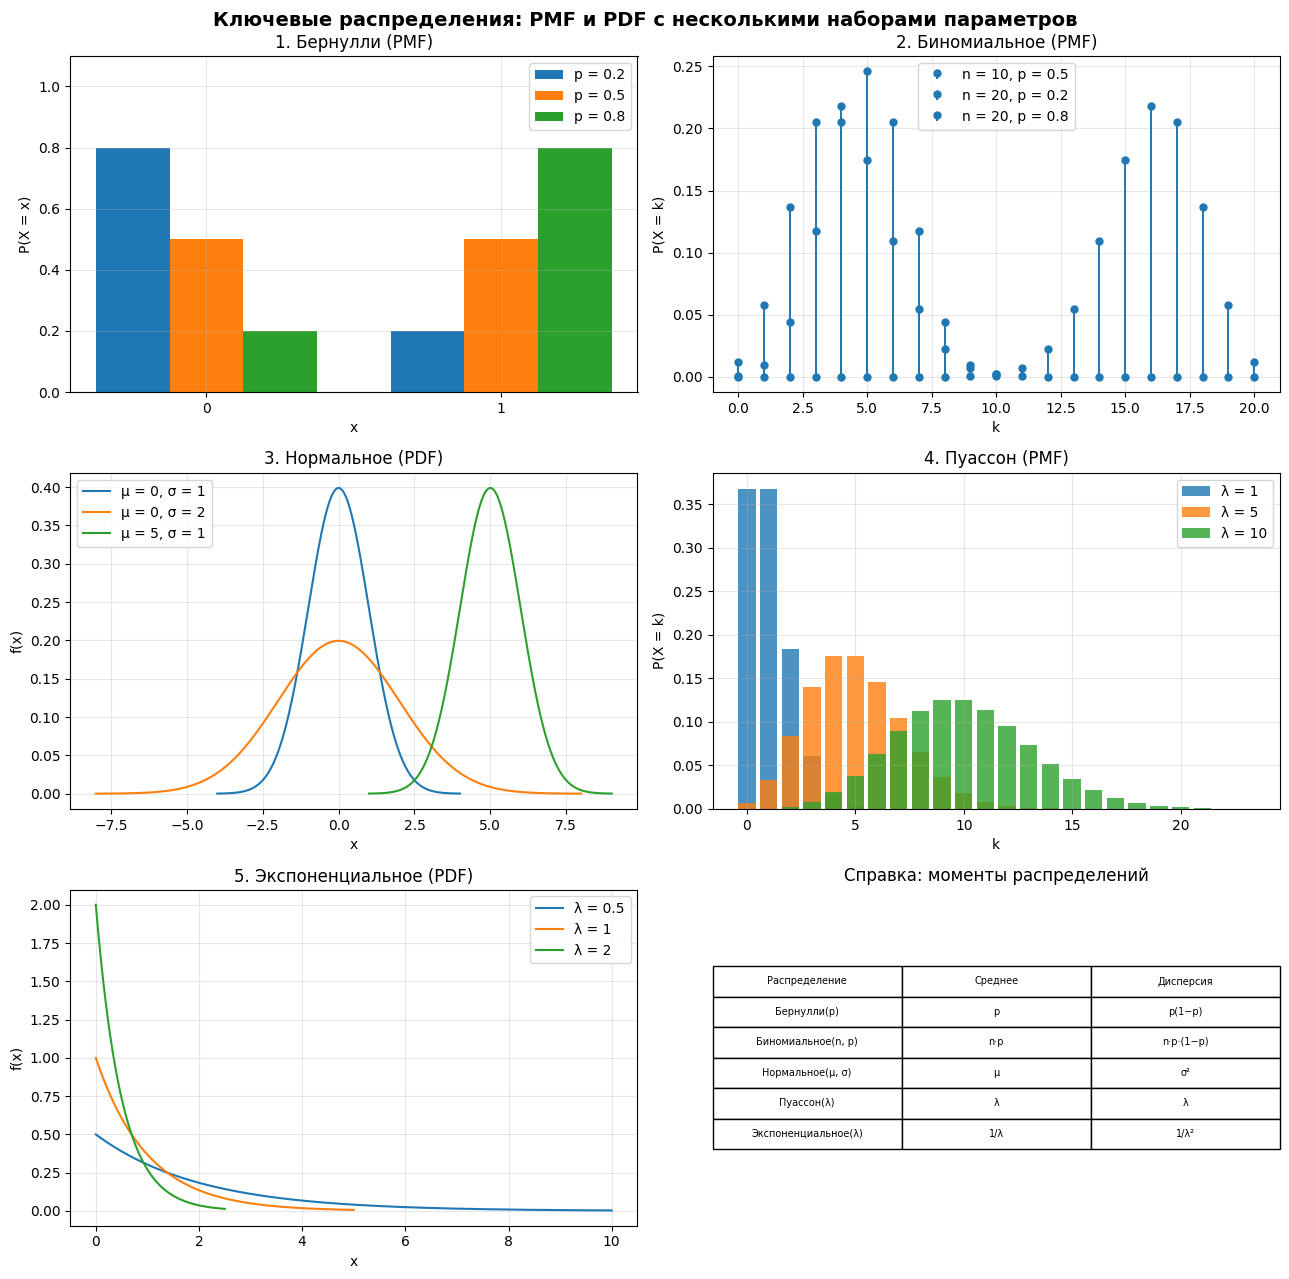

In [6]:
# --- Вспомогательная функция для биномиального коэффициента ---
def binom_coef(n, k):
    """C(n, k) через мультипликативную формулу.
    Не переполняется на больших n, в отличие от прямого факториала."""
    if k < 0 or k > n:
        return 0.0
    k = min(k, n - k)
    result = 1.0
    for i in range(1, k + 1):
        result = result * (n - k + i) / i
    return result

def factorial(x):
    """Факториал целого числа (для Пуассона k маленький — переполнения нет)."""
    result = 1.0
    for i in range(2, int(x) + 1):
        result *= i
    return result

# --- Параметры из условия ---
array_p = [0.2, 0.5, 0.8]                              # Бернулли
array_params_bin = [(10, 0.5), (20, 0.2), (20, 0.8)]   # Биномиальное
array_params_norm = [(0, 1), (0, 2), (5, 1)]           # Нормальное
array_lambda = [1, 5, 10]                              # Пуассон
array_lambda_exp = [0.5, 1, 2]                         # Экспоненциальное

fig, axes = plt.subplots(3, 2, figsize=(13, 13))
fig.suptitle("Ключевые распределения: PMF и PDF с несколькими наборами параметров",
            fontsize=14, fontweight='bold')

# --- 1. Бернулли (PMF) ---
ax = axes[0, 0]
width = 0.25
for i, p in enumerate(array_p):
    xs = [x + (i - 1) * width for x in (0, 1)]   # сдвиг, чтобы столбцы не слипались
    ys = [1 - p, p]
    ax.bar(xs, ys, width=width, label=f"p = {p}")
ax.set_title("1. Бернулли (PMF)")
ax.set_xlabel("x")
ax.set_ylabel("P(X = x)")
ax.set_xticks([0, 1])
ax.set_ylim(0, 1.1)
ax.legend()
ax.grid(alpha=0.3)

# --- 2. Биномиальное (PMF) ---
ax = axes[0, 1]
for n, p in array_params_bin:
    X_bin = list(range(n + 1))
    Y_bin = [binom_coef(n, k) * (p ** k) * ((1 - p) ** (n - k)) for k in X_bin]
    markerline, stemlines, baseline = ax.stem(
        X_bin, Y_bin,
        label=f'n = {n}, p = {p}',
        basefmt=' ',          # убираем горизонтальную базовую линию — она мешает
    )
    plt.setp(stemlines, linewidth=1.4)
    plt.setp(markerline, markersize=5)

ax.set_title('2. Биномиальное (PMF)')
ax.set_xlabel('k')
ax.set_ylabel('P(X = k)')
ax.legend()
ax.grid(alpha=0.3)

# --- 3. Нормальное (PDF) ---
ax = axes[1, 0]
for mu, sigma in array_params_norm:
    X_norm = np.linspace(mu - 4 * sigma, mu + 4 * sigma, 1000)
    Y_norm = (1 / (sigma * math.sqrt(2 * math.pi))) * np.exp(-((X_norm - mu)**2) / (2 * sigma**2))
    ax.plot(X_norm, Y_norm, label=f"μ = {mu}, σ = {sigma}")
ax.set_title("3. Нормальное (PDF)")
ax.set_xlabel("x")
ax.set_ylabel("f(x)")
ax.legend()
ax.grid(alpha=0.3)

# --- 4. Пуассон (PMF) ---
ax = axes[1, 1]
for lam in array_lambda:
    max_k = math.ceil(lam + 4 * math.sqrt(lam))   # эмпирическая граница хвоста
    X_pois = list(range(max_k + 1))
    Y_pois = [(lam**k) * math.exp(-lam) / factorial(k) for k in X_pois]
    ax.bar(X_pois, Y_pois, label=f"λ = {lam}", alpha=0.8)
ax.set_title("4. Пуассон (PMF)")
ax.set_xlabel("k")
ax.set_ylabel("P(X = k)")
ax.legend()
ax.grid(alpha=0.3)

# --- 5. Экспоненциальное (PDF) ---
ax = axes[2, 0]
for lam in array_lambda_exp:
    X_exp = np.linspace(0, 5 / lam, 1000)   # граница, где плотность почти 0
    Y_exp = lam * np.exp(-lam * X_exp)      # поэлементная операция
    ax.plot(X_exp, Y_exp, label=f"λ = {lam}")
ax.set_title("5. Экспоненциальное (PDF)")
ax.set_xlabel("x")
ax.set_ylabel("f(x)")
ax.legend()
ax.grid(alpha=0.3)

# --- Справочная таблица: моменты распределений ---
ax = axes[2, 1]
ax.axis("off")
rows = [
    ('Распределение', 'Среднее', 'Дисперсия'),
    ('Бернулли(p)', 'p', 'p(1−p)'),
    ('Биномиальное(n, p)', 'n·p', 'n·p·(1−p)'),
    ('Нормальное(μ, σ)', 'μ', 'σ²'),
    ('Пуассон(λ)', 'λ', 'λ'),
    ('Экспоненциальное(λ)', '1/λ', '1/λ²'),
]
table = ax.table(cellText=rows[1:], colLabels=rows[0], loc='center', cellLoc='center')
table.scale(1, 1.6)
ax.set_title("Справка: моменты распределений")

plt.tight_layout()
plt.savefig("task1_distributions.png", dpi=150, bbox_inches='tight')
plt.show()

#### 2. Симуляция Бернулли → Биномиальное. Сгенерируйте 10 000 раз сумму 50 бернулли с p=0.3. Постройте гистограмму и наложите PMF биномиального.

#### 3. ЦПТ на равномерном. Усредняйте n = 1, 2, 5, 10, 30 равномерно распределённых чисел. Покажите, как гистограмма меняется от прямоугольника к колоколу.

#### 4. Q-Q plot. Постройте Q-Q plot для нормально распределённых данных и для экспоненциальных. Объясните разницу.

#### 5. Оценка параметров. Сгенерируйте 1000 точек из N(μ=3, σ=2). Оцените μ, σ методом моментов и методом максимального правдоподобия.

#### 6. 2D нормальное. Сгенерируйте N(0, Σ) с Σ = [[1, 0.9], [0.9, 1]]. Постройте scatter и контуры плотности.

#### 7. Тяжёлые хвосты. Сравните, насколько часто бывают «события 5σ» у нормального и у Коши. Сделайте 1 000 000 семплов каждого.

#### 8. Бета как prior. Подбросили 5 монет, 4 орла. Используйте Beta(2, 2) как prior. Постройте posterior.